# Does the k-means theme mix change between 2001 and 2024? (pilot)

RQ2 asks how much of the change in psychology's knowledge extent (KE) comes from a shifting mix of themes. That decomposition only has something to explain if the mix actually moves. In the full pool, OpenAlex's 7 subfields barely move (the largest change from 2001–03 to 2022–24 is 3.5 points). This notebook checks whether the 7 k-means themes from Week 2 move more.

**Data.** The Week 2 pilot is 2,400 KE-eligible pool papers, 100 per year from 2001 to 2024, with their SPECTER2 proximity vectors (`data/validation/citation_pairs/`). The full pool is not embedded yet, so the themes here are the pilot's own k-means clusters. No KE is computed.

**Rule, fixed before running** (decision log, 2026-11-02):
- The mix shift is the **total variation distance (TVD)** between two windows' theme shares, which is half the sum of the absolute share differences. It equals the share of papers that would have to change theme to turn one mix into the other.
- The verdict is **one permutation test** of TVD between 2001–03 and 2022–24 (300 papers each), and the mix counts as changed if p < 0.05. TVD is above 0 even when nothing changes, because two samples of 300 never match exactly. So the size is reported as TVD minus its **noise level**, the average TVD when the window labels are shuffled.
- Per-theme changes are shown with bootstrap intervals and described, not tested one by one.
- Whatever the result, RQ2 stays as designed and k-means stays the main unit.

The functions are in `src/theme_mix.py` (tests in `src/test_theme_mix.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from src import theme_mix as tm

TABLES, FIGURES = Path("outputs/tables"), Path("outputs/figures")
A, B = "2001–03", "2022–24"   # the decomposition's reference and end windows
N_PERM = 10_000
pd.set_option("display.max_colwidth", 120)

# chart style as in Week 2: thin lines, recessive grid, text in ink colors (not series colors)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax, grid="y"):
    ax.grid(axis=grid, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

### Step 1: rebuild the 7 themes

k-means with the Week 2 settings (k = 7, 10 starts, seed 20261026) on the raw 768-dimensional vectors, fitted once on all 2,400 papers so every year counts equally. The assertion checks that the cluster sizes match Week 2, so these are the same themes as the t-SNE map.

The short names come from each theme's most common OpenAlex topics and its most distinctive words (the Week 2 TF-IDF method). Two names differ from the first draft of the slides. Theme 4's words are about metaphor, philosophy and phenomenology rather than psychopathology, and theme 6's are about vision, tasks and driving rather than ergonomics alone.

In [2]:
X, papers = tm.load_pilot()
labels, model = tm.fit_themes(X, k=7)
assert tuple(np.bincount(labels)) == tm.WEEK2_SIZES, "not the Week 2 clusters"

papers["theme"] = labels
papers["window"] = tm.window_of(papers["publication_year"])
assert papers.groupby("window").size().eq(300).all()   # 8 windows of 3 years x 100 papers

texts = (papers["title"].fillna("") + ". " + papers["abstract"]).tolist()
themes = pd.DataFrame({"name": pd.Series(tm.THEME_NAMES),
                       "papers": np.bincount(labels),
                       "top OpenAlex topics": tm.top_topics(papers["primary_topic"], labels).map("; ".join),
                       "most distinctive words (TF-IDF)": pd.Series(tm.distinctive_words(texts, labels))})
themes.index.name = "theme"
themes

,name,papers,top OpenAlex topics,most distinctive words (TF-IDF)
theme,,,,
0,Teaching and teams,289,Innovative Teaching and Learning Methods; Team Dynamics and Performance; Educational Games and Gamification,"learning, students, training, team, student, management, design, teaching, education, teams"
1,Well-being and personality,417,Psychological Well-being and Life Satisfaction; Personality Traits and Psychology; Student Stress and Coping,"students, self, personality, psychological, relationship, motivation, positive, intelligence, emotional intelligence..."
2,Mental health and suicide,497,Suicide and Self-Harm Studies; Sleep and related disorders; Posttraumatic Stress Disorder Research,"patients, health, depression, mental, suicide, treatment, disorder, psychiatric, mental health, disorders"
3,Reading and language,253,Reading and Literacy Development; Second Language Acquisition and Learning; Phonetics and Phonology Research,"reading, language, vocabulary, english, comprehension, word, words, learning, children, learners"
4,Psychoanalysis and theory,363,"Psychoanalysis and Psychopathology Research; Phenomenology and Existential Philosophy; Memory, Trauma, and Commemora...","metaphor, experience, nature, understanding, conceptual, philosophy, war, therapeutic, political, phenomenology"
5,Child and family development,323,"Child and Adolescent Psychosocial and Emotional Development; Bullying, Victimization, and Aggression; Child Abuse an...","children, child, parents, adolescents, parent, behavior, family, adolescent, mothers, development"
6,Perception and human factors,258,Ergonomics and Musculoskeletal Disorders; Human-Automation Interaction and Safety; Primate Behavior and Ecology,"visual, task, human, driving, driver, stimuli, conditions, brain, effects, performance"


### Step 2: the main test, 2001–03 vs 2022–24

Each theme's share in the two windows, the change in points, and a bootstrap 95% interval for the change (papers resampled within each window). Then the pre-set test. A chi-square test of homogeneity (7 themes × 2 windows, df 6) is the standard cross-check.

In [3]:
change = tm.bootstrap_diff(papers["theme"], papers["window"], A, B)
change.insert(1, "name", change["theme"].map(tm.THEME_NAMES))
change.to_csv(TABLES / "pilot_theme_mix_change.csv", index=False)

main = tm.permutation_test(papers["theme"], papers["window"], A, B, n_perm=N_PERM)
two = papers["window"].isin([A, B])
chi = tm.chi_square(papers.loc[two, "theme"], papers.loc[two, "window"])

print(f"Mix shift (TVD): {main['tvd']:.3f}, i.e. {main['tvd']:.1%} of papers would have to change theme")
print(f"Noise level: {main['noise']:.3f} (95% of shuffles below {main['null_95']:.3f})")
print(f"Shift above noise: {main['above_noise']:.3f}")
print(f"Permutation p = {main['p']:.4f} ({N_PERM:,} shuffles); chi-square = {chi['chi2']:.1f}, df {chi['df']}, p = {chi['p']:.4f}")
print("Verdict by the pre-set rule:", "the mix changed" if main["p"] < 0.05 else "no change detected")
(change.set_index("theme").assign(**{c: lambda d, c=c: (d[c] * 100).round(1) for c in [f"share {A}", f"share {B}", "change", "lo", "hi"]})
       .rename(columns={"lo": "change, 2.5%", "hi": "change, 97.5%"}))

Mix shift (TVD): 0.113, i.e. 11.3% of papers would have to change theme
Noise level: 0.079 (95% of shuffles below 0.120)
Shift above noise: 0.035
Permutation p = 0.0794 (10,000 shuffles); chi-square = 11.2, df 6, p = 0.0827
Verdict by the pre-set rule: no change detected


,name,share 2001–03,share 2022–24,change,"change, 2.5%","change, 97.5%"
theme,,,,,,
0,Teaching and teams,12.0,15.0,3.0,-2.3,8.3
1,Well-being and personality,14.0,20.3,6.3,0.3,12.3
2,Mental health and suicide,22.3,23.0,0.7,-6.0,7.3
3,Reading and language,8.0,7.7,-0.3,-4.7,4.0
4,Psychoanalysis and theory,17.0,11.3,-5.7,-11.3,-0.3
5,Child and family development,17.0,11.7,-5.3,-11.0,0.3
6,Perception and human factors,9.7,11.0,1.3,-3.7,6.0


The figure shows the same table. Each row is a theme, the blue dot its share in 2001–03 and the orange dot its share in 2022–24. The numbers on the right are the change in points with its 95% interval. Themes are sorted from the largest gain to the largest loss.

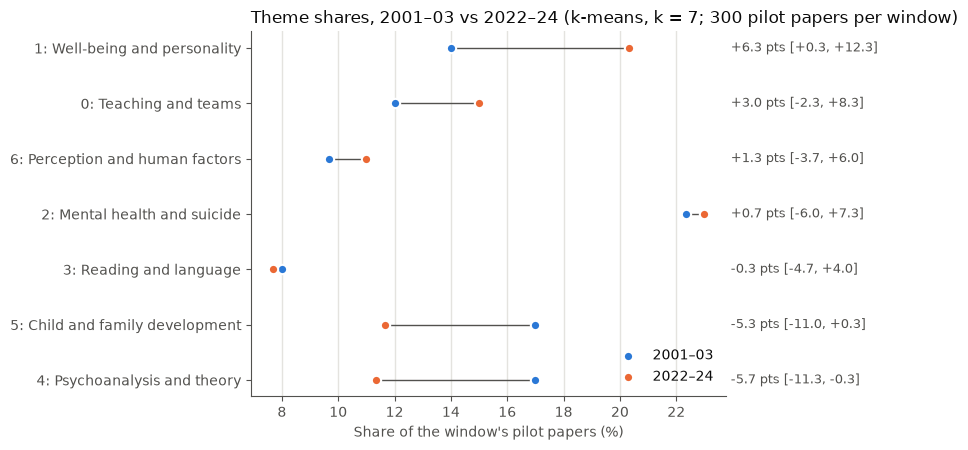

In [4]:
order = change.sort_values("change")
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(order))
ax.hlines(y, order[f"share {A}"] * 100, order[f"share {B}"] * 100, color=MUTED, linewidth=1)
ax.scatter(order[f"share {A}"] * 100, y, s=45, color=COLORS[0], zorder=3, label=A, edgecolors="white", linewidths=1.5)
ax.scatter(order[f"share {B}"] * 100, y, s=45, color=COLORS[1], zorder=3, label=B, edgecolors="white", linewidths=1.5)
ax.set_yticks(y, [f"{t}: {n}" for t, n in zip(order["theme"], order["name"])], color=INK)
for yi, (_, r) in zip(y, order.iterrows()):
    ax.annotate(f"{r['change'] * 100:+.1f} pts [{r['lo'] * 100:+.1f}, {r['hi'] * 100:+.1f}]", (1.01, yi),
                xycoords=("axes fraction", "data"), va="center", fontsize=9, color=MUTED)
ax.set_xlabel("Share of the window's pilot papers (%)", color=MUTED)
ax.set_title(f"Theme shares, {A} vs {B} (k-means, k = 7; 300 pilot papers per window)", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
style_axes(ax, grid="x")
fig.tight_layout()
fig.savefig(FIGURES / "pilot_theme_mix_dumbbell.png", dpi=200, bbox_inches="tight")
plt.show()

### Step 3: the whole period

The two windows above are the ends of the period. Here are all 8 three-year windows (300 papers each), with Wilson 95% intervals, to see whether the change builds up steadily or comes from noise at the two ends. The chi-square test now asks whether the mix differs anywhere across the 8 windows (df 42). Evenness is the entropy of the mix divided by its maximum. It is 1 if all 7 themes had equal shares and 0 if every paper were in one theme, and it is shown as description only.

Chi-square across the 8 windows = 49.9, df 42, p = 0.1879


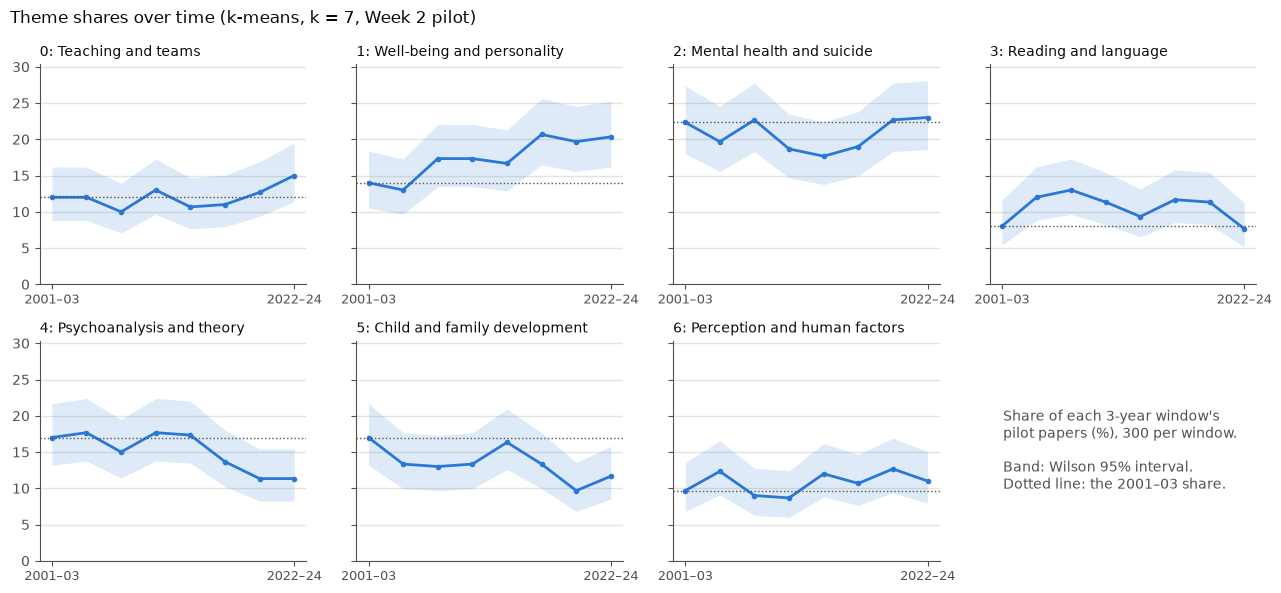

,window,n,evenness,lo,hi
0,2001–03,300,0.974,0.948,0.985
1,2004–06,300,0.990,0.968,0.995
2,2007–09,300,0.978,0.952,0.988
3,2010–12,300,0.985,0.962,0.992
4,2013–15,300,0.986,0.965,0.993
5,2016–18,300,0.984,0.960,0.991
6,2019–21,300,0.976,0.950,0.987
7,2022–24,300,0.968,0.938,0.981


In [5]:
by_window = tm.shares(papers["theme"], papers["window"])
by_window.insert(2, "name", by_window["theme"].map(tm.THEME_NAMES))
by_window.to_csv(TABLES / "pilot_theme_mix_shares.csv", index=False)
chi_all = tm.chi_square(papers["theme"], papers["window"])
print(f"Chi-square across the 8 windows = {chi_all['chi2']:.1f}, df {chi_all['df']}, p = {chi_all['p']:.4f}")

windows = sorted(by_window["window"].unique())
mid = np.array([int(w[:4]) + 1 for w in windows])
top = by_window["hi"].max() * 100 * 1.08
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for k, ax in zip(range(7), axes.flat):
    t = by_window[by_window["theme"] == k].set_index("window").loc[windows]
    ax.fill_between(mid, t["lo"] * 100, t["hi"] * 100, color=COLORS[0], alpha=0.15, linewidth=0)
    ax.plot(mid, t["share"] * 100, color=COLORS[0], linewidth=2, marker="o", markersize=3)
    ax.axhline(t["share"].iloc[0] * 100, color=MUTED, linewidth=1, linestyle=":")   # the 2001–03 share
    ax.set_title(f"{k}: {tm.THEME_NAMES[k]}", color=INK, loc="left", fontsize=10)
    ax.set_ylim(0, top)
    style_axes(ax)
axes.flat[7].axis("off")
axes.flat[7].text(0.05, 0.5, "Share of each 3-year window's\npilot papers (%), 300 per window.\n\nBand: Wilson 95% interval.\n"
                  "Dotted line: the 2001–03 share.", color=MUTED, fontsize=10, va="center",
                  transform=axes.flat[7].transAxes)
for ax in axes.flat[:7]:
    ax.set_xticks([2002, 2023], [A, B], fontsize=9)
    ax.tick_params(labelbottom=True)
fig.suptitle("Theme shares over time (k-means, k = 7, Week 2 pilot)", color=INK, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "pilot_theme_mix_windows.png", dpi=200, bbox_inches="tight")
plt.show()

tm.evenness_by_group(papers["theme"], papers["window"]).round(3)

### Step 4: the same test with OpenAlex subfields

The same TVD test, with OpenAlex's 7 psychology subfields in place of the k-means themes, first on the same 2,400 pilot papers and then on the full pool (every KE-eligible paper of the 2001–03 and 2022–24 pools, about 30,000 per window). The full pool has 100 times as many papers per window, so its p-value is not comparable with the pilot's. The comparison is by the size of the shift above noise.

In [6]:
pool = pd.read_parquet(tm.POOL, columns=["publication_year", "title", "abstract", "primary_subfield"])
pool = pool[tm.ke_eligible(pool)].copy()
pool["window"] = tm.window_of(pool["publication_year"])

tests = pd.DataFrame([
    {"partition": "k-means themes, k = 7", "papers": "pilot", **main},
    {"partition": "OpenAlex subfields", "papers": "pilot",
     **tm.permutation_test(papers["primary_subfield"], papers["window"], A, B, n_perm=N_PERM)},
    {"partition": "OpenAlex subfields", "papers": "full pool",
     **tm.permutation_test(pool["primary_subfield"], pool["window"], A, B, n_perm=N_PERM)},
])
sub_change = tm.bootstrap_diff(pool["primary_subfield"], pool["window"], A, B, n_boot=2_000)
display(tests.round(4))
(sub_change.set_index("theme").rename_axis("subfield (full pool)").mul(100).round(1))

,partition,papers,n_a,n_b,categories,tvd,noise,above_noise,null_95,p
0,"k-means themes, k = 7",pilot,300,300,7,0.1133,0.0786,0.0347,0.1200,0.0794
1,OpenAlex subfields,pilot,300,300,7,0.1300,0.0649,0.0651,0.1067,0.0091
2,OpenAlex subfields,full pool,29367,29844,7,0.0481,0.0067,0.0414,0.0110,0.0001


,share 2001–03,share 2022–24,change,lo,hi
subfield (full pool),,,,,
Applied Psychology,3.5,2.9,-0.6,-0.9,-0.3
Clinical Psychology,33.7,31.2,-2.5,-3.3,-1.8
Developmental and Educational Psychology,16.8,20.2,3.5,2.8,4.1
Experimental and Cognitive Psychology,17.3,16.9,-0.4,-1.0,0.2
General Psychology,1.1,0.3,-0.8,-0.9,-0.7
Neuropsychology and Physiological Psychology,1.5,1.0,-0.5,-0.7,-0.3
Social Psychology,26.2,27.6,1.4,0.7,2.1


**How large a shift can 300 papers per window detect?** The full pool gives a benchmark of a real shift, namely how much the subfield mix actually moved. The simulation draws 300 papers from the full pool's 2001–03 subfield mix and 300 from its 2022–24 mix, runs the same permutation test, and repeats this 1,000 times. The share of runs with p < 0.05 is the chance that the pilot design detects a shift of that size. The same simulation with no shift gives the false-positive rate, which should be about 5%.

In [7]:
p_early = sub_change[f"share {A}"].to_numpy()
p_late = sub_change[f"share {B}"].to_numpy()
power = pd.Series({
    "no shift (false-positive rate)": tm.detection_rate(p_early, p_early, 300, 300),
    "the subfields' full-pool shift": tm.detection_rate(p_early, p_late, 300, 300),
    "the same shift, 1,000 papers per window": tm.detection_rate(p_early, p_late, 1_000, 1_000),
}, name="share of runs with p < 0.05")
power.rename_axis("scenario").to_csv(TABLES / "pilot_theme_mix_power.csv")
power

no shift (false-positive rate)             0.034
the subfields' full-pool shift             0.140
the same shift, 1,000 papers per window    0.445
Name: share of runs with p < 0.05, dtype: float64

### Step 5: does the answer depend on k or on the random start?

**Other k.** The same test at k = 5 and k = 10. More clusters mean more shares that can differ by chance, so the noise level rises with k, and each k is read against its own noise level.

**Random starts.** k-means can settle on different solutions from different starting points. Ten further seeds at k = 7 show how closely each fit agrees with the main one (adjusted Rand index, 1 = identical) and whether the test gives the same answer.

In [8]:
for k in (5, 10):
    lab_k, _ = tm.fit_themes(X, k=k)
    tests.loc[len(tests)] = {"partition": f"k-means themes, k = {k}", "papers": "pilot",
                             **tm.permutation_test(lab_k, papers["window"], A, B, n_perm=N_PERM)}
tests.to_csv(TABLES / "pilot_theme_mix_tests.csv", index=False)
display(tests[["partition", "papers", "n_a", "n_b", "categories", "tvd", "noise", "above_noise", "p"]].round(4))

seeds = []
for seed in range(1, 11):
    lab_s, _ = tm.fit_themes(X, k=7, seed=seed)
    r = tm.permutation_test(lab_s, papers["window"], A, B, n_perm=N_PERM)
    seeds.append({"seed": seed, "ARI with main fit": adjusted_rand_score(labels, lab_s),
                  "sizes": sorted(np.bincount(lab_s).tolist(), reverse=True),
                  "tvd": r["tvd"], "above_noise": r["above_noise"], "p": r["p"]})
seeds = pd.DataFrame(seeds)
seeds.to_csv(TABLES / "pilot_theme_mix_sensitivity.csv", index=False)
seeds.round(3)

,partition,papers,n_a,n_b,categories,tvd,noise,above_noise,p
0,"k-means themes, k = 7",pilot,300,300,7,0.1133,0.0786,0.0347,0.0794
1,OpenAlex subfields,pilot,300,300,7,0.1300,0.0649,0.0651,0.0091
2,OpenAlex subfields,full pool,29367,29844,7,0.0481,0.0067,0.0414,0.0001
3,"k-means themes, k = 5",pilot,300,300,5,0.1367,0.0644,0.0723,0.0061
4,"k-means themes, k = 10",pilot,300,300,10,0.1800,0.0965,0.0835,0.0018


,seed,ARI with main fit,sizes,tvd,above_noise,p
0,1,0.898,"[505, 402, 355, 334, 291, 276, 237]",0.097,0.018,0.230
1,2,0.941,"[496, 433, 360, 320, 278, 263, 250]",0.127,0.048,0.031
2,3,0.791,"[500, 393, 367, 328, 309, 272, 231]",0.160,0.082,0.002
3,4,0.835,"[478, 440, 351, 318, 307, 265, 241]",0.147,0.068,0.008
4,5,0.820,"[478, 420, 356, 318, 315, 283, 230]",0.140,0.061,0.013
5,6,0.940,"[497, 407, 359, 324, 293, 284, 236]",0.120,0.042,0.062
6,7,0.860,"[498, 399, 384, 304, 291, 291, 233]",0.127,0.048,0.036
7,8,0.926,"[501, 416, 362, 325, 276, 260, 260]",0.127,0.048,0.039
8,9,0.892,"[483, 419, 351, 339, 289, 262, 257]",0.137,0.058,0.015
9,10,0.778,"[443, 439, 353, 315, 311, 276, 263]",0.163,0.084,0.002


### Step 6: what this means for RQ2

**By the pre-set rule, no change is detected.** To turn the 2001–03 theme mix into the 2022–24 mix, 11.3% of pilot papers would have to change theme. Shuffling the window labels already gives 7.9% on average, so the shift above noise is 3.5% of papers and the permutation p-value is 0.08. The chi-square test agrees (p = 0.08). Across all 8 windows the mix does not differ clearly either (p = 0.19).

**The pilot is too small to settle the question.** Four results point the same way.
- With 300 papers per window, a shift as large as the one the subfields actually show in the full pool (4.8% of papers) reaches p < 0.05 in only 14% of simulated pilots. Even with 1,000 papers per window it would be found less than half the time.
- The main fit's p = 0.08 sits close to the line. At k = 5 and k = 10 the test gives p < 0.01, and 8 of the 10 other random starts at k = 7 give p < 0.05. These are not independent confirmations, because they are re-partitions of the same 600 papers. But they show that the answer depends on where k-means happens to settle.
- The theme partition itself is not yet stable on 2,400 papers. The other starts agree with the main fit at an adjusted Rand index of only 0.78 to 0.94.
- The same pilot papers grouped by OpenAlex subfield show a larger shift (6.5% above noise, p = 0.009) than the full pool does for the same subfields (4.1%). Small windows can exaggerate a shift as easily as they can hide one.

**What seems to move (description only).**
- *Gains:* well-being and personality grows from 14.0% to 20.3%, fairly steadily over the period, and teaching and teams grows from 12.0% to 15.0%.
- *Losses:* psychoanalysis and theory falls from 17.0% to 11.3%, mostly after 2016–18, and child and family development falls from 17.0% to 11.7%.
- *About the same at the two ends:* mental health and suicide (it dips in the middle years and comes back), reading and language, and perception and human factors.

Evenness stays between 0.97 and 0.99, so the field is not concentrating into fewer themes.

**For RQ2, the design stays as it is** (decision log, 2026-11-02). In the full pool each window has about 30,000 papers, and there noise alone moves less than 1% of papers, so a shift of a few percent will be clearly measurable. Two points carry forward.
1. Check k-means stability across random starts on the full pool before the decomposition. If the fits disagree, report the decomposition for more than one start.
2. A shifting mix does not by itself change KE. That depends on whether the growing and shrinking themes sit near the field's edge or near its centre, which only the fixed-mix KE comparison can show.